# Sustainable Import Patterns of Tissue Parent Rolls in Peru (2020–2025)
### Reproducible analysis notebook — Angela Milén Acosta Ticona (UNMSM)

**Paradigm:** Positivist (quantitative, retrospective, observational).
**Data:** Veritrade import records (SUNAT customs declarations), HS 4803.00.90, 4818.20 and 4818.90, January 2020 – December 2025,
filtered to **parent rolls (bobinas) for local conversion** into personal-use paper.

| RQ | Question | Section |
|---|---|---|
| RQ1 | Which import profiles exist among parent-roll imports, and how does the sustainability signal vary across them? | 6 |
| RQ2 | Which customs variables predict a proxy-indicated sustainable import? | 7 |
| RQ3 / H5 | Did the share of sustainable parent-roll imports change between 2020 and 2025? | 4 |
| Extra | Is there a price difference (US$ FOB per kg) between recycled-fibre and other parent rolls? | 5 |

> **ES:** Este notebook reproduce todo el análisis desde el archivo limpio. Cada sección tiene una nota corta en español.
> Si se vuelve a ejecutar con el mismo archivo, los resultados deben ser idénticos (semillas fijas y huella MD5).

## 0. Environment and reproducibility settings
Fixed random seed, library versions printed, and all paths relative to this folder.
> **ES:** Fijamos la semilla y mostramos las versiones de las librerías para que otra persona obtenga los mismos resultados.

In [1]:
import hashlib, platform, re, unicodedata, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import sklearn, scipy, statsmodels, xgboost, shap
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
DATA = Path('data/bobinas_limpio.xlsx')
FIG, OUT = Path('figures'), Path('outputs')
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# chart style: thin marks, recessive grid, one accent hue
BLUE, ORANGE, INK, MUTED, SURFACE = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': '#c9c8c3',
                     'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.axisbelow': True, 'font.size': 10, 'axes.titleweight': 'bold'})

for lib in (np, pd, sklearn, scipy, statsmodels, xgboost, shap, matplotlib):
    print(f'{lib.__name__:12s} {lib.__version__}')
print('python      ', platform.python_version())

numpy        2.5.3
pandas       3.0.5
sklearn      1.9.1
scipy        1.18.1
statsmodels  0.15.0
xgboost      3.4.1
shap         0.54.1
matplotlib   3.11.2
python       3.13.16


## 1. Load data and verify its fingerprint
The MD5 hash proves that the analysed file is exactly the cleaned file produced by `cleaning/build_clean.py`
(rule-based screening + documented expert decisions in `cleaning/decisiones_manuales.csv`).
> **ES:** La huella MD5 es como el "número de serie" del archivo: si alguien cambia una sola celda, la huella cambia.

In [2]:
md5 = hashlib.md5(DATA.read_bytes()).hexdigest()
print('MD5:', md5)
EXPECTED_MD5 = 'f2d7e5e54cc455749e50e57bb96dbfea'
assert md5 == EXPECTED_MD5, 'The data file is not the registered cleaned version'

df = pd.read_excel(DATA)
assert len(df) == 2994 and not df.duplicated().any()
print(f'{len(df):,} records | {df.Fecha.min():%Y-%m-%d} to {df.Fecha.max():%Y-%m-%d}')
print(df['Partida Aduanera'].value_counts().rename('records').to_string())

MD5: f2d7e5e54cc455749e50e57bb96dbfea


2,994 records | 2020-01-02 to 2025-12-30
Partida Aduanera
4803009000    2844
4818900000      97
4818200000      53


### 1.1 Anonymisation
Firm-level trade data are commercially sensitive. Importers and suppliers are replaced by stable codes
(ordered by first appearance) before any output is produced; names never appear in tables or figures.
> **ES:** Reemplazamos los nombres de empresas por códigos (IMP_001, SUP_001...) para proteger datos comerciales.

In [3]:
def codes(s, prefix):
    s = s.fillna('NO DISPONIBLE').astype(str).str.strip()
    order = {v: f'{prefix}_{i+1:03d}' for i, v in enumerate(pd.unique(s))}
    return s.map(order)

df = df.sort_values(['Fecha', 'DUA / DAM']).reset_index(drop=True)
df['importer'] = codes(df['Importador'], 'IMP')
exp = df['Embarcador / Exportador'].replace('NO DISPONIBLE', np.nan)
df['supplier_known'] = exp.notna().astype(int)
df['supplier'] = codes(exp, 'SUP')
df.loc[exp.isna(), 'supplier'] = 'SUP_UNKNOWN'
df = df.drop(columns=['Importador', 'Embarcador / Exportador', 'Cod. Tributario'])
print(df.importer.nunique(), 'importers |', df.supplier.nunique() - 1, 'known suppliers |',
      f'{1 - df.supplier_known.mean():.0%} of records without supplier')

74 importers | 121 known suppliers | 48% of records without supplier


## 2. Variables and sustainability proxies
Customs records contain **no environmental field**, so sustainability is measured with explicit text proxies
taken from the commercial description (normalised to upper case without accents):

| Variable | Rule | Meaning |
|---|---|---|
| `cert` | `FSC`, `PEFC`, `ISO 14001`, `ECOLABEL` | certification claim |
| `recycled` | `RECICLAD*`, `RECYCL*` | recycled-fibre claim |
| **`sust`** (label) | `cert` OR `recycled` | **proxy-indicated sustainable import** |
| `fibre` | recycled / virgin / not declared | declared fibre type (virgin = `VIRGEN`, `VIRGIN`, `PURE`, `100% CELULOSA`) |

Other variables: FOB per kg (unit value), net kg, grammage (GSM, parsed from text), product type (towel / toilet / napkin),
HS code, origin country, customs office, transport mode, inspection channel, month.
> **ES:** Como la aduana no tiene un campo "sostenible", usamos palabras en la descripción (FSC, reciclado) como indicadores
> (proxies). Es la principal limitación del estudio, por eso se valida en la Sección 8.

In [4]:
DESC = ['Descripcion Comercial'] + [f'Descripcion{i}' for i in range(1, 6)]
norm = lambda s: unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode().upper()
txt = df[DESC].fillna('').astype(str).agg(' '.join, axis=1).map(norm)

df['cert'] = txt.str.contains(r'\bFSC\b|\bPEFC\b|ISO\s*14001|ECO.?LABEL').astype(int)
df['recycled'] = txt.str.contains(r'RECICLAD|RECYCL').astype(int)
df['sust'] = (df.cert | df.recycled).astype(int)
virgin = txt.str.contains(r'VIRGEN|VIRGIN|\bPURE\b|\bPUR[AO]\b|100\s*%\s*CELULOSA')
df['fibre'] = np.select([df.recycled == 1, virgin], ['recycled', 'virgin'], 'not declared')

def gsm(t):
    m = re.search(r'(?:GSM|G/M2|GRAMAJE|SUB(?:STANCE)?|BASIS(?:\s+GSM)?)\s*[:=]?\s*(\d{2}(?:[.,]\d+)?)', t) or \
        re.search(r'(\d{2}(?:[.,]\d+)?)\s*(?:GSM|G/M2|GRS?\b|GRAMOS|G\b)', t)
    v = float(m.group(1).replace(',', '.')) if m else np.nan
    return v if 10 <= v <= 60 else np.nan
df['gsm'] = txt.map(gsm)
df['product'] = np.select([txt.str.contains(r'TOALLA|TOWEL'), txt.str.contains(r'HIGIENICO|TOILET|BATH'),
                           txt.str.contains(r'SERVILLETA|NAPKIN')], ['towel', 'toilet', 'napkin'], 'other/unspecified')

df['year'] = df.Fecha.dt.year
df['month'] = df.Fecha.dt.month
df['kg'] = df['Kg Neto']
df['fob'] = df['U$ FOB Tot']
df['usd_kg'] = df.fob / df.kg
df['hs'] = df['Partida Aduanera'].astype(str).str[:6]
top_c = df['Pais de Origen'].value_counts().index[:8]
df['origin'] = df['Pais de Origen'].where(df['Pais de Origen'].isin(top_c), 'OTHER')
df['channel'] = df['Canal'].fillna('NOT RECORDED')

print(f"sust = 1 in {df.sust.sum()} records ({df.sust.mean():.1%}); cert {df.cert.sum()}, recycled {df.recycled.sum()}")
print(f"GSM parsed for {df.gsm.notna().mean():.0%} of records")
print(df.fibre.value_counts().to_string()); print(df['product'].value_counts().to_string())

sust = 1 in 133 records (4.4%); cert 20, recycled 123
GSM parsed for 90% of records
fibre
not declared    1892
virgin           979
recycled         123
product
towel                1448
toilet                927
napkin                567
other/unspecified      52


### 2.1 Descriptive overview by year
> **ES:** Resumen por año: número de registros, toneladas, valor FOB y cuántos tienen señal de sostenibilidad.

In [5]:
yr = df.groupby('year').agg(records=('sust', 'size'), sust=('sust', 'sum'), cert=('cert', 'sum'),
                            recycled=('recycled', 'sum'), tonnes=('kg', lambda x: x.sum() / 1e3),
                            fob_musd=('fob', lambda x: x.sum() / 1e6), usd_kg_median=('usd_kg', 'median'))
yr['sust_share_records_%'] = 100 * yr.sust / yr.records
yr['sust_share_kg_%'] = 100 * df[df.sust == 1].groupby('year').kg.sum() / df.groupby('year').kg.sum()
yr.round(2).to_csv(OUT / 'table1_by_year.csv')
yr.round(2)

,records,sust,cert,recycled,tonnes,fob_musd,usd_kg_median,sust_share_records_%,sust_share_kg_%
year,,,,,,,,,
2020,585,42,10,42,19036.02,17.64,0.96,7.18,6.01
2021,470,6,0,6,28614.20,28.74,0.97,1.28,0.46
2022,633,22,0,22,27093.84,37.50,1.43,3.48,1.52
2023,355,26,0,26,20973.65,23.89,1.22,7.32,2.25
2024,352,12,0,12,9517.94,10.93,1.19,3.41,1.76
2025,599,25,10,15,17877.38,19.27,1.07,4.17,2.34


## 3. Data-quality screen: Isolation Forest
Unsupervised anomaly detection on log net kg, log FOB/kg and grammage flags records whose values are implausible
(e.g. a typing error in weight or value). Anomalies are **not deleted**: every test is reported with and without them
(Section 9).
> **ES:** El algoritmo marca registros "raros" (por ejemplo, un precio de US$ 795 por kg, que es casi seguro un error de digitación).
> No los borramos; los usamos en el análisis de sensibilidad.

In [6]:
from sklearn.ensemble import IsolationForest
X_if = pd.DataFrame({'log_kg': np.log10(df.kg), 'log_usd_kg': np.log10(df.usd_kg),
                     'gsm': df.gsm.fillna(df.gsm.median())})
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=SEED).fit(X_if)
df['anomaly'] = (iso.predict(X_if) == -1).astype(int)
print(df.anomaly.sum(), 'records flagged as anomalous')
df.loc[df.anomaly == 1, ['year', 'hs', 'kg', 'usd_kg', 'gsm', 'product']].sort_values('usd_kg').round(2) \
  .to_csv(OUT / 'anomalies.csv', index=False)
print(df.loc[df.anomaly == 1, 'usd_kg'].describe().round(2).to_string())
print('normal records, FOB/kg range:', df.loc[df.anomaly == 0, 'usd_kg'].quantile([.01, .99]).round(2).tolist())

60 records flagged as anomalous
count     60.00
mean      15.07
std      102.39
min        0.32
25%        1.07
50%        1.39
75%        1.77
max      794.72
normal records, FOB/kg range: [0.74, 1.71]


## 4. RQ3 / H5 — Did the sustainable share change over time?
* **Trend test:** logistic regression of `sust` on year (odds ratio per year).
* **H5:** share in 2024–2025 > share in 2020–2021 (one-sided two-proportion z-test).
* 95% Wilson confidence intervals per year.
> **ES:** Probamos si la proporción de bobinas con señal sostenible sube con los años. El *odds ratio* > 1 indicaría aumento.

Trend: odds ratio per year = 0.953 (95% CI 0.864–1.052), p = 0.3432
H5: 2024–25 = 3.9% vs 2020–21 = 4.5%; z = -0.73, one-sided p = 0.7678
H5 NOT supported at alpha = 0.05


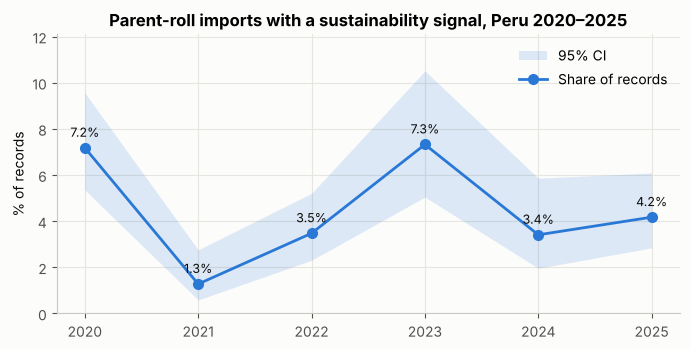

In [7]:
ci = yr.apply(lambda r: proportion_confint(r.sust, r.records, method='wilson'), axis=1)
yr['lo'], yr['hi'] = [100 * c[0] for c in ci], [100 * c[1] for c in ci]

trend = smf.logit('sust ~ I(year - 2020)', data=df).fit(disp=0)
or_, (lo_, hi_) = np.exp(trend.params.iloc[1]), np.exp(trend.conf_int().iloc[1])
print(f'Trend: odds ratio per year = {or_:.3f} (95% CI {lo_:.3f}–{hi_:.3f}), p = {trend.pvalues.iloc[1]:.4f}')

early, late = df[df.year.isin([2020, 2021])], df[df.year.isin([2024, 2025])]
z, p = proportions_ztest([late.sust.sum(), early.sust.sum()], [len(late), len(early)], alternative='larger')
print(f'H5: 2024–25 = {late.sust.mean():.1%} vs 2020–21 = {early.sust.mean():.1%}; z = {z:.2f}, one-sided p = {p:.4f}')
print('H5 supported' if p < 0.05 else 'H5 NOT supported at alpha = 0.05')

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.fill_between(yr.index, yr.lo, yr.hi, color=BLUE, alpha=.15, linewidth=0, label='95% CI')
ax.plot(yr.index, yr['sust_share_records_%'], color=BLUE, lw=2, marker='o', ms=7, label='Share of records')
for x, y in yr['sust_share_records_%'].items():
    ax.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, 8), ha='center', color=INK, fontsize=9)
ax.set(title='Parent-roll imports with a sustainability signal, Peru 2020–2025', xlabel='', ylabel='% of records',
       ylim=(0, max(yr.hi) * 1.15))
ax.legend(frameon=False, loc='upper right'); fig.tight_layout(); fig.savefig(FIG / 'fig1_trend.png', dpi=200)

## 5. Price: do recycled-fibre parent rolls cost less per kg?
Mann–Whitney U test (no normality assumption) and an OLS model of log(FOB/kg) controlling for year, product type and HS code
(robust HC3 standard errors). Anomalies excluded.
> **ES:** Comparamos el costo unitario (US$ FOB por kg). El modelo controla por año y tipo de producto para no confundir efectos.

               count    25%    50%    75%
fibre                                    
virgin         962.0  0.980  1.080  1.194
recycled       109.0  0.898  0.961  1.100
not declared  1863.0  1.000  1.158  1.295
Mann–Whitney recycled vs rest: U = 93398, p = 2.976e-12
Recycled vs virgin, other things equal: -12.9% (95% CI -15.2% to -10.5%), p = 6.135e-24


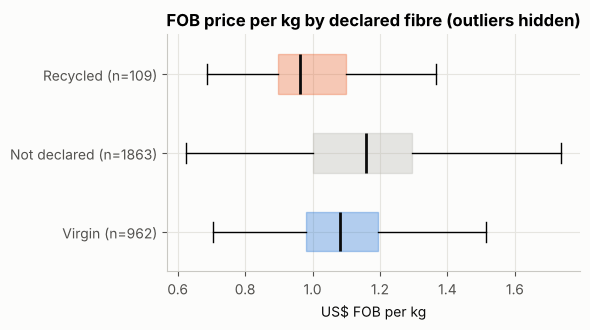

In [8]:
d = df[df.anomaly == 0].copy()
d['fibre'] = pd.Categorical(d.fibre, ['virgin', 'recycled', 'not declared'])
print(d.groupby('fibre', observed=True).usd_kg.describe()[['count', '25%', '50%', '75%']].round(3).to_string())
u, p_u = stats.mannwhitneyu(d.loc[d.recycled == 1, 'usd_kg'], d.loc[d.recycled == 0, 'usd_kg'])
print(f'Mann–Whitney recycled vs rest: U = {u:.0f}, p = {p_u:.4g}')

ols = smf.ols('np.log(usd_kg) ~ C(fibre) + C(year) + C(product) + C(hs)', data=d).fit(cov_type='HC3')
b = ols.params['C(fibre)[T.recycled]']; lo_b, hi_b = ols.conf_int().loc['C(fibre)[T.recycled]']
print(f'Recycled vs virgin, other things equal: {100*(np.exp(b)-1):+.1f}% '
      f'(95% CI {100*(np.exp(lo_b)-1):+.1f}% to {100*(np.exp(hi_b)-1):+.1f}%), p = {ols.pvalues["C(fibre)[T.recycled]"]:.4g}')

fig, ax = plt.subplots(figsize=(6, 3.4))
groups = [d.loc[d.fibre == g, 'usd_kg'] for g in ['virgin', 'not declared', 'recycled']]
bp = ax.boxplot(groups, vert=False, widths=.5, showfliers=False, patch_artist=True,
                medianprops=dict(color=INK, lw=2))
for patch, c in zip(bp['boxes'], [BLUE, '#b9b8b2', ORANGE]):
    patch.set(facecolor=c, alpha=.35, edgecolor=c)
ax.set_yticks([1, 2, 3], [f'Virgin (n={len(groups[0])})', f'Not declared (n={len(groups[1])})', f'Recycled (n={len(groups[2])})'])
ax.set(title='FOB price per kg by declared fibre (outliers hidden)', xlabel='US$ FOB per kg')
fig.tight_layout(); fig.savefig(FIG / 'fig2_price.png', dpi=200)

## 6. RQ1 — Import profiles (K-Means)
Records are clustered on standardised log kg, log FOB/kg, grammage and product type. The number of clusters *k* is chosen
by the silhouette score (k = 2…8, fixed seed). The sustainability signal is then compared across profiles (chi-square test).
> **ES:** K-Means agrupa las importaciones parecidas (volumen, precio, gramaje, producto) en "perfiles". Luego vemos en qué perfil
> aparece más la señal sostenible.

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

c = df[df.anomaly == 0].copy()
Xk = pd.concat([pd.DataFrame({'log_kg': np.log10(c.kg), 'log_usd_kg': np.log10(c.usd_kg),
                              'gsm': c.gsm.fillna(c.gsm.median())}, index=c.index),
                pd.get_dummies(c['product'], dtype=float)], axis=1)
Xs = StandardScaler().fit_transform(Xk)
sil = {k: silhouette_score(Xs, KMeans(k, n_init=20, random_state=SEED).fit_predict(Xs), random_state=SEED)
       for k in range(2, 9)}
k_best = max(sil, key=sil.get)
print('silhouette:', {k: round(v, 3) for k, v in sil.items()}, '-> k =', k_best)
c['profile'] = KMeans(k_best, n_init=20, random_state=SEED).fit_predict(Xs) + 1

prof = c.groupby('profile').agg(records=('sust', 'size'), median_tonnes=('kg', lambda x: x.median() / 1e3),
                                median_usd_kg=('usd_kg', 'median'), median_gsm=('gsm', 'median'),
                                main_product=('product', lambda x: x.mode()[0]),
                                main_origin=('origin', lambda x: x.mode()[0]),
                                sust_share_pct=('sust', lambda x: 100 * x.mean()))
chi2, p_chi, dof, _ = stats.chi2_contingency(pd.crosstab(c.profile, c.sust))
print(f'Sustainability signal across profiles: chi2 = {chi2:.1f}, dof = {dof}, p = {p_chi:.4g}')
prof.round(2).to_csv(OUT / 'table2_profiles.csv')
prof.round(2)

silhouette: {2: 0.32, 3: 0.435, 4: 0.468, 5: 0.46, 6: 0.494, 7: 0.472, 8: 0.472} -> k = 6
Sustainability signal across profiles: chi2 = 85.2, dof = 5, p = 6.778e-17


,records,median_tonnes,median_usd_kg,median_gsm,main_product,main_origin,sust_share_pct
profile,,,,,,,
1,712,16.81,1.25,17.0,toilet,BOLIVIA,3.51
2,406,18.76,1.12,34.0,towel,INDONESIA,11.58
3,563,28.86,1.05,21.0,napkin,INDONESIA,3.55
4,993,17.45,1.15,20.0,towel,CHINA,2.01
5,51,28.00,1.05,19.5,other/unspecified,INDONESIA,11.76
6,209,0.84,0.78,23.0,toilet,PORTUGAL,0.48


## 7. RQ2 — Which customs variables predict a sustainable import?
**Design (no leakage):**
* Predictors use **only structured customs fields** plus grammage and product type; no sustainability or fibre words.
* **Temporal hold-out:** train 2020–2024, test 2025 (the model never sees the future).
* **Grouped cross-validation** inside the training period (5 folds × 20 seeds): records of the same importer never appear in both train and validation folds.
* **Baselines:** majority class and logistic regression. **Metric:** PR-AUC (average precision), suited to a rare positive class.
* **Comparison:** XGBoost vs logistic regression with the corrected resampled t-test (Nadeau & Bengio, 2003).
> **ES:** Entrenamos con 2020–2024 y probamos con 2025, como si predijéramos el futuro. Comparamos XGBoost contra modelos simples:
> si no los supera, el modelo complejo no se justifica.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

CAT = ['hs', 'origin', 'Aduana', 'Via', 'channel', 'product']
NUM = ['log_kg', 'log_usd_kg', 'gsm', 'supplier_known', 'month']
m = df.copy()
m['log_kg'], m['log_usd_kg'] = np.log10(m.kg), np.log10(m.usd_kg)
for col in CAT:
    m[col] = m[col].fillna('NA').astype(str)
train, test = m[m.year <= 2024], m[m.year == 2025]
print(f'train {len(train)} records ({train.sust.sum()} positive) | test {len(test)} ({test.sust.sum()} positive)')

pre = lambda: ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10), CAT),
                                 ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                                                   ('sc', StandardScaler())]), NUM)])
pos_w = (train.sust == 0).sum() / train.sust.sum()
models = {
    'Majority class': Pipeline([('pre', pre()), ('clf', DummyClassifier(strategy='prior'))]),
    'Logistic regression': Pipeline([('pre', pre()), ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', C=0.5))]),
    'XGBoost': Pipeline([('pre', pre()), ('clf', XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_w, eval_metric='logloss',
                          random_state=SEED, n_jobs=1))]),
}

# repeated grouped CV (5 folds x 20 seeds = 100 scores) on the training period
cv_scores = {k: [] for k in models}
n_tr, n_te = [], []
for rep in range(20):
    sgk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + rep)
    for tr, va in sgk.split(train, train.sust, groups=train.importer):
        n_tr.append(len(tr)); n_te.append(len(va))
        for name, mdl in models.items():
            mdl.fit(train.iloc[tr], train.sust.iloc[tr])
            prob = mdl.predict_proba(train.iloc[va])[:, 1]
            cv_scores[name].append(average_precision_score(train.sust.iloc[va], prob))
cv = pd.DataFrame(cv_scores)
print('Grouped CV PR-AUC (mean ± sd):'); print((cv.mean().round(3).astype(str) + ' ± ' + cv.std().round(3).astype(str)).to_string())

def corrected_ttest(a, b, n_train, n_test):
    d_ = np.asarray(a) - np.asarray(b); k = len(d_)
    var = d_.var(ddof=1) * (1 / k + n_test / n_train)
    t = d_.mean() / np.sqrt(var)
    return t, 2 * stats.t.sf(abs(t), k - 1)
t, p_t = corrected_ttest(cv['XGBoost'], cv['Logistic regression'], np.mean(n_tr), np.mean(n_te))
print(f'XGBoost vs logistic regression (corrected resampled t-test): t = {t:.2f}, p = {p_t:.4f}')

train 2395 records (108 positive) | test 599 (25 positive)


Grouped CV PR-AUC (mean ± sd):
Majority class         0.045 ± 0.005
Logistic regression     0.47 ± 0.261
XGBoost                0.519 ± 0.263
XGBoost vs logistic regression (corrected resampled t-test): t = 0.59, p = 0.5551


In [11]:
rows = []
for name, mdl in models.items():
    mdl.fit(train, train.sust)
    prob = mdl.predict_proba(test)[:, 1]
    rows.append({'model': name, 'PR-AUC': average_precision_score(test.sust, prob),
                 'ROC-AUC': roc_auc_score(test.sust, prob) if name != 'Majority class' else 0.5,
                 'balanced accuracy': balanced_accuracy_score(test.sust, prob >= 0.5)})
holdout = pd.DataFrame(rows).set_index('model').round(3)
print(f'2025 hold-out (positive rate = {test.sust.mean():.3f}, i.e. the PR-AUC of a random guess):')
holdout.to_csv(OUT / 'table3_models_holdout.csv')
cv.agg(['mean', 'std']).T.round(3).to_csv(OUT / 'table3b_models_cv.csv')
holdout

2025 hold-out (positive rate = 0.042, i.e. the PR-AUC of a random guess):


,PR-AUC,ROC-AUC,balanced accuracy
model,,,
Majority class,0.042,0.500,0.500
Logistic regression,0.386,0.725,0.727
XGBoost,0.415,0.853,0.696


### 7.0 Disaggregated results on the 2025 test set (XGBoost, threshold 0.5)
Results are reported per group, not only as an overall average (Model Card requirement).
> **ES:** Revisamos si el modelo funciona igual de bien en cada grupo (partida, producto, proveedor conocido o no).

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score
pred = (models['XGBoost'].predict_proba(test)[:, 1] >= 0.5).astype(int)
t2 = test.assign(pred=pred)
rows = []
for factor in ['hs', 'product', 'supplier_known']:
    for g, x in t2.groupby(factor):
        rows.append({'factor': factor, 'group': g, 'records': len(x), 'positives': int(x.sust.sum()),
                     'recall': recall_score(x.sust, x.pred, zero_division=0) if x.sust.sum() else np.nan,
                     'precision': precision_score(x.sust, x.pred, zero_division=0) if x.pred.sum() else np.nan})
rows.append({'factor': 'overall', 'group': 'all', 'records': len(t2), 'positives': int(t2.sust.sum()),
             'recall': recall_score(t2.sust, t2.pred), 'precision': precision_score(t2.sust, t2.pred, zero_division=0)})
dis = pd.DataFrame(rows).round(3)
print('F1 overall:', round(f1_score(t2.sust, t2.pred), 3))
dis.to_csv(OUT / 'table3c_disaggregated.csv', index=False)
dis

F1 overall: 0.344


,factor,group,records,positives,recall,precision
0,hs,480300,528,25,0.440,0.282
1,hs,481820,21,0,NaN,NaN
2,hs,481890,50,0,NaN,NaN
3,product,napkin,24,0,NaN,NaN
4,product,other/unspecified,24,6,0.000,NaN
5,product,toilet,69,3,0.667,1.000
6,product,towel,482,16,0.562,0.243
7,supplier_known,0,561,23,0.478,0.282
8,supplier_known,1,38,2,0.000,NaN
9,overall,all,599,25,0.440,0.282


### 7.1 Which variables drive the prediction? (SHAP)
SHAP values show how much each predictor pushes a record towards "sustainable". Computed for the XGBoost model on the 2025 test set.
> **ES:** SHAP explica el modelo: qué variables (país, precio, partida...) pesan más en la predicción. Esto responde RQ2.

gsm                   2.1310
log_usd_kg            0.9833
log_kg                0.9376
origin_VIETNAM        0.8909
origin_CHINA          0.5434
origin_INDONESIA      0.4608
month                 0.2581
Aduana_DESAGUADERO    0.2471
channel_VERDE         0.2407
supplier_known        0.2261
dtype: float32

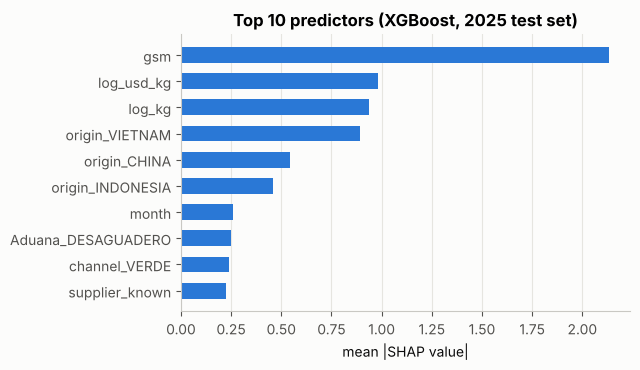

In [13]:
xgb = models['XGBoost']
Xt = xgb.named_steps['pre'].transform(test)
Xt = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
names = [n.split('__', 1)[1] for n in xgb.named_steps['pre'].get_feature_names_out()]
sv = shap.TreeExplainer(xgb.named_steps['clf']).shap_values(Xt)
imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False)
imp.round(4).to_csv(OUT / 'table4_shap_importance.csv', header=['mean_abs_shap'])

top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(top.index, top.values, color=BLUE, height=.6)
ax.set(title='Top 10 predictors (XGBoost, 2025 test set)', xlabel='mean |SHAP value|')
ax.grid(axis='y', visible=False); fig.tight_layout(); fig.savefig(FIG / 'fig3_shap.png', dpi=200)
top[::-1].round(4)

## 8. Proxy validation sample (two raters, Cohen's kappa)
A stratified random sample (all positive records up to 60, plus negatives to reach 200) is exported **without the automatic label**.
Two raters label each record independently (1 = the description shows recycled fibre or a sustainability certification).
Agreement is measured with Cohen's kappa (rater A vs rater B) and the proxy is checked against the consensus label.
> **ES:** Tú y una segunda persona etiquetan a mano 200 registros sin ver la etiqueta automática. El kappa mide si ambos coinciden
> (≥ 0.80 es muy bueno). Así se demuestra que el proxy es válido. El archivo para etiquetar queda en `outputs/`.

In [14]:
from sklearn.metrics import cohen_kappa_score
rng = np.random.default_rng(SEED)
pos = df[df.sust == 1].sample(min(60, df.sust.sum()), random_state=SEED)
neg = df[df.sust == 0].sample(200 - len(pos), random_state=SEED)
sample = pd.concat([pos, neg]).sample(frac=1, random_state=SEED)
sample['sample_id'] = [f'S{i+1:03d}' for i in range(len(sample))]
sheet = sample[['sample_id', 'Descripcion Comercial'] + DESC[1:]].assign(rater_label='', notes='')
sheet.to_csv(OUT / 'validation_sample_to_label.csv', index=False, encoding='utf-8-sig')
sample[['sample_id', 'sust']].to_csv(OUT / 'validation_key_DO_NOT_SHOW_RATERS.csv', index=False)
print(f'{len(sheet)} records exported ({len(pos)} positive by the proxy).')

def kappa_report(file_a, file_b):
    a, b = pd.read_csv(file_a), pd.read_csv(file_b)
    key = pd.read_csv(OUT / 'validation_key_DO_NOT_SHOW_RATERS.csv')
    x = a[['sample_id', 'rater_label']].merge(b[['sample_id', 'rater_label']], on='sample_id', suffixes=('_a', '_b')).merge(key)
    k_ab = cohen_kappa_score(x.rater_label_a, x.rater_label_b)
    agree = x[x.rater_label_a == x.rater_label_b]
    k_proxy = cohen_kappa_score(agree.rater_label_a, agree.sust)
    return pd.Series({'kappa rater A vs B': k_ab, 'kappa consensus vs proxy': k_proxy, 'n agreed': len(agree)}).round(3)
# usage after labelling: kappa_report('outputs/rater_A.csv', 'outputs/rater_B.csv')

200 records exported (60 positive by the proxy).


## 9. Sensitivity analysis
Main results re-estimated (a) without anomalies, (b) without the COVID-19 years 2020–2021, (c) with each proxy alone.
> **ES:** Repetimos las pruebas cambiando supuestos. Si las conclusiones no cambian, el resultado es robusto.

In [15]:
def trend_or(data, label):
    r = smf.logit(f'{label} ~ I(year - 2020)', data=data).fit(disp=0)
    return np.exp(r.params.iloc[1]), r.pvalues.iloc[1]

scen = {'All records': df, 'Without anomalies': df[df.anomaly == 0], 'Without 2020–2021': df[df.year >= 2022]}
rows = []
for s, data in scen.items():
    for label in ['sust', 'recycled', 'cert']:
        if data.loc[data[label] == 1, 'year'].nunique() < 3:   # too few years with positives: trend not estimable
            continue
        o, p_ = trend_or(data, label)
        rows.append({'scenario': s, 'label': label, 'positives': int(data[label].sum()),
                     'share_%': round(100 * data[label].mean(), 2), 'OR per year': f'{o:.3f}', 'p': f'{p_:.4f}'})
sens = pd.DataFrame(rows)
sens.to_csv(OUT / 'table5_sensitivity.csv', index=False)
sens

,scenario,label,positives,share_%,OR per year,p
0,All records,sust,133,4.44,0.953,0.3432
1,All records,recycled,123,4.11,0.884,0.0206
2,Without anomalies,sust,119,4.06,0.981,0.7108
3,Without anomalies,recycled,109,3.72,0.904,0.0725
4,Without 2020–2021,sust,85,4.38,0.998,0.9857
5,Without 2020–2021,recycled,75,3.87,0.867,0.1410


## 10. Summary of findings

In [16]:
print(f'''
1. {len(df):,} parent-roll import records (2020–2025), {df.kg.sum()/1e6:.1f} thousand tonnes, US$ {df.fob.sum()/1e6:.1f} million FOB.
2. Only {df.sust.mean():.1%} of records ({100*df[df.sust==1].kg.sum()/df.kg.sum():.1f}% of tonnage) carry a sustainability signal.
3. RQ3: odds ratio per year = {or_:.2f} (p = {trend.pvalues.iloc[1]:.3f}); H5 {"supported" if p < .05 else "not supported"} (p = {p:.3f}).
4. Price: recycled vs virgin parent rolls {100*(np.exp(b)-1):+.1f}% FOB/kg (p = {ols.pvalues["C(fibre)[T.recycled]"]:.3g}).
5. RQ1: {k_best} import profiles; the sustainability signal differs across them (chi2 p = {p_chi:.3g}).
6. RQ2: 2025 hold-out PR-AUC — XGBoost {holdout.loc["XGBoost","PR-AUC"]}, logistic {holdout.loc["Logistic regression","PR-AUC"]},
   majority {holdout.loc["Majority class","PR-AUC"]}; top predictor: {imp.index[0]}.
''')


1. 2,994 parent-roll import records (2020–2025), 123.1 thousand tonnes, US$ 138.0 million FOB.
2. Only 4.4% of records (2.2% of tonnage) carry a sustainability signal.
3. RQ3: odds ratio per year = 0.95 (p = 0.343); H5 not supported (p = 0.768).
4. Price: recycled vs virgin parent rolls -12.9% FOB/kg (p = 6.14e-24).
5. RQ1: 6 import profiles; the sustainability signal differs across them (chi2 p = 6.78e-17).
6. RQ2: 2025 hold-out PR-AUC — XGBoost 0.415, logistic 0.386,
   majority 0.042; top predictor: gsm.



## 11. Limitations
* **Proxy validity:** absence of a "recycled" or "FSC" word does not prove conventional fibre; the proxy measures *declared* claims.
  Validation in Section 8 (kappa) and supplier checks in public FSC/PEFC registries address this.
* **Scope:** only parent rolls declared under HS 4803.00.90, 4818.20 and 4818.90; selection rules are documented in `cleaning/`.
* **Observational design:** associations, not causal effects.
* **Missing data:** supplier is not reported in a large share of records.

*Reproduce:* `pip install -r requirements.txt` then *Run All*. Expected data MD5: `f2d7e5e54cc455749e50e57bb96dbfea`.